In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import xgboost as xgb
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

In [2]:
Mnist_train = pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\Aya\Machan learning\Machine_learning_Fils\Mnist\mnist_train.csv")
Mnist_test= pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\Aya\Machan learning\Machine_learning_Fils\Mnist\mnist_test.csv")

In [3]:
Mnist_test.shape

(10000, 785)

In [4]:
Number_mnist = pd.concat([Mnist_train, Mnist_test],ignore_index=False)

In [6]:
Number_mnist.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
Number_mnist['label'].value_counts()

label
1    7877
7    7293
3    7141
2    6990
9    6958
0    6903
6    6876
8    6825
4    6824
5    6313
Name: count, dtype: int64

In [8]:
Number_mnist.shape

(70000, 785)

In [10]:
Number_mnist.info()

<class 'pandas.DataFrame'>
Index: 70000 entries, 0 to 9999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 419.8 MB


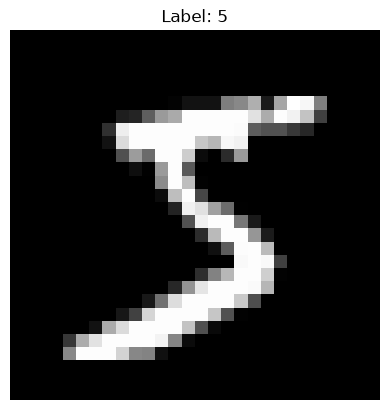

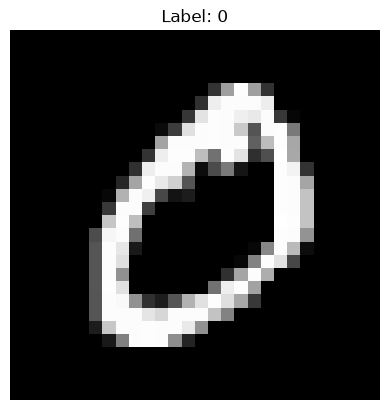

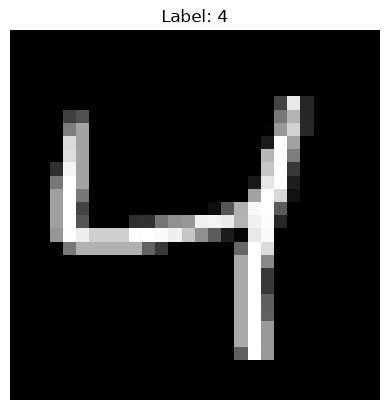

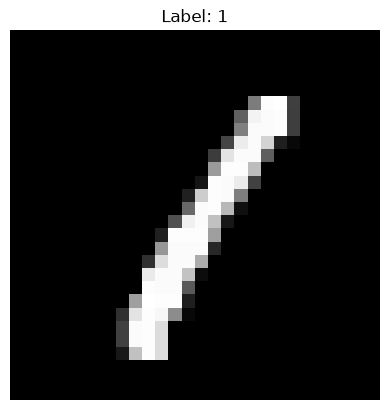

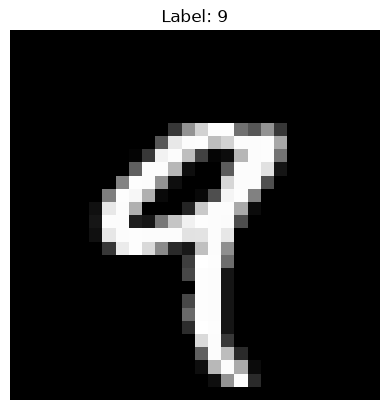

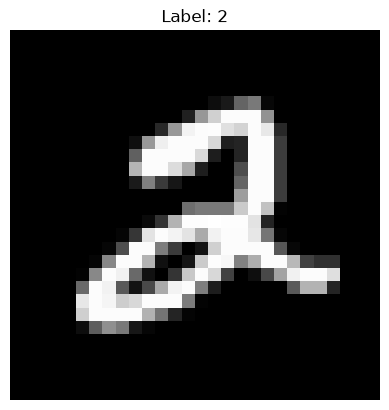

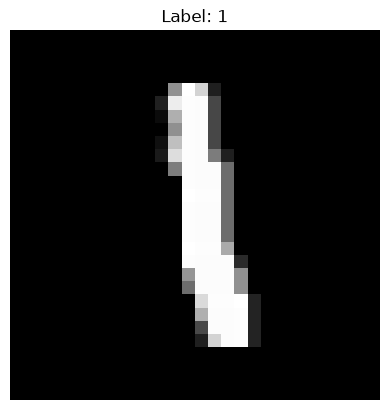

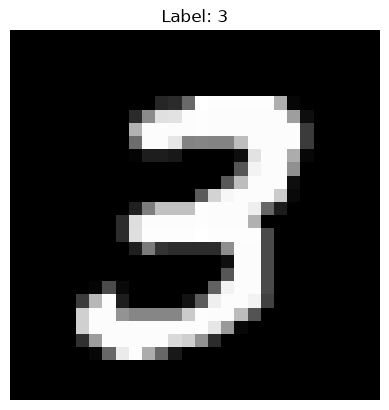

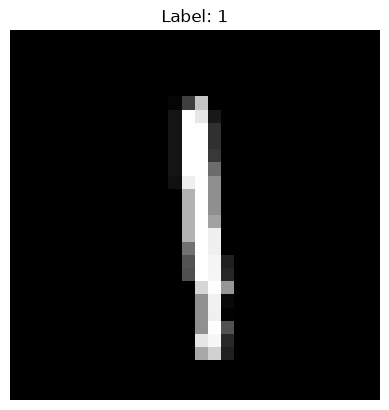

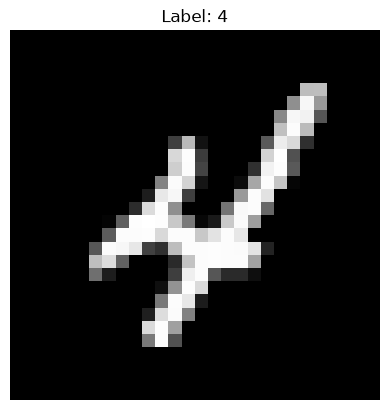

In [13]:
def display_image(index):
    pixels = Number_mnist.iloc[index,1:].values.reshape(28, 28)
    image = Number_mnist.iloc[index,0]
    plt.imshow(pixels, cmap='gray')
    plt.title(f'Label: {image}')
    plt.axis('off')
    plt.show()

for i in range(10):
        display_image(i)

In [15]:
Number_mnist.isna().sum().sum()

np.int64(0)

In [16]:
Number_mnist.shape

(70000, 785)

In [17]:
Number_mnist_X = Number_mnist.drop('label', axis=1)
Number_mnist_y = Number_mnist['label']

In [18]:
Number_mnist_X=Number_mnist_X / 255.0

In [20]:
X_train, X_test, y_train, y_test = train_test_split(Number_mnist_X, Number_mnist_y, test_size=0.2, random_state=42)

xgb_model = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=10,
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)


In [22]:
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {accuracy * 100:.2f}%")


Accuracy: 97.86%


In [23]:
print("\nConfusion Matrix:")
conf_mat = confusion_matrix(y_test, y_pred)
print(conf_mat)


Confusion Matrix:
[[1324    0    3    0    1    2    2    1    8    2]
 [   0 1579    5    4    2    0    0    6    3    1]
 [   1    3 1352    1    5    0    3    6    6    3]
 [   1    0   12 1388    0    6    1    9    4   12]
 [   2    0    1    0 1271    0    2    2    1   16]
 [   1    3    1   10    1 1246    7    0    4    0]
 [   3    0    0    0    5    6 1378    0    4    0]
 [   1    2   13    2    3    0    0 1469    1   12]
 [   1    4    6    5    3    4    5    5 1319    5]
 [   4    6    1    7   13    2    0    8    5 1374]]


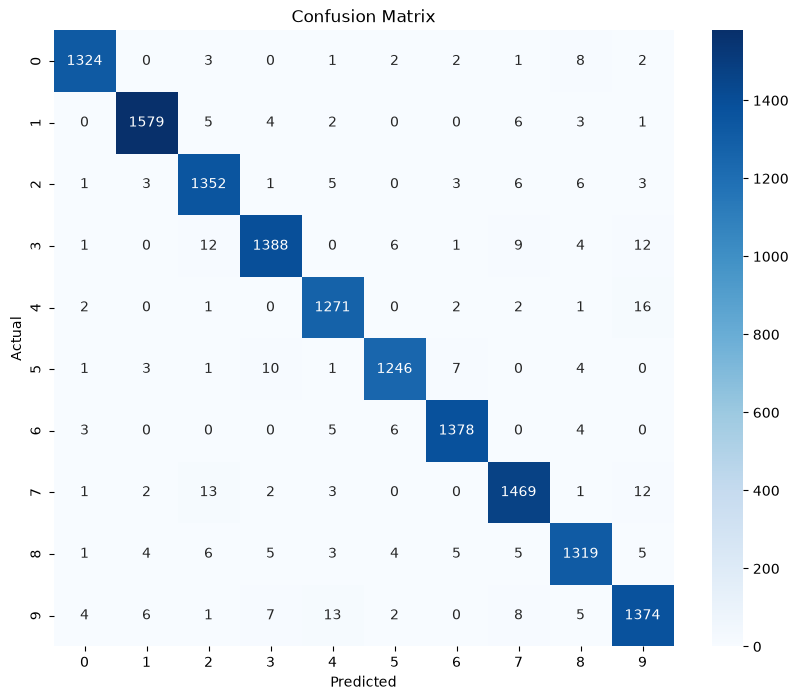

In [24]:
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig("confusion_matrix.png")
plt.show()

In [25]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       0.99      0.99      0.99      1600
           2       0.97      0.98      0.97      1380
           3       0.98      0.97      0.97      1433
           4       0.97      0.98      0.98      1295
           5       0.98      0.98      0.98      1273
           6       0.99      0.99      0.99      1396
           7       0.98      0.98      0.98      1503
           8       0.97      0.97      0.97      1357
           9       0.96      0.97      0.97      1420

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000



Training SVS (Support Vector Classifier) Model

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(Number_mnist_X, Number_mnist_y, test_size=0.2, random_state=42)
svc_model = SVC(
    kernel='rbf',
    C=5.0,
    gamma='scale',
    random_state=42
)


svc_model.fit(X_train, y_train)


In [34]:
y_pred_svc = svc_model.predict(X_test)

In [35]:
accuracy = accuracy_score(y_test, y_pred_svc)
print(f"\nAccuracy: {accuracy * 100:.2f}%")


Accuracy: 98.18%


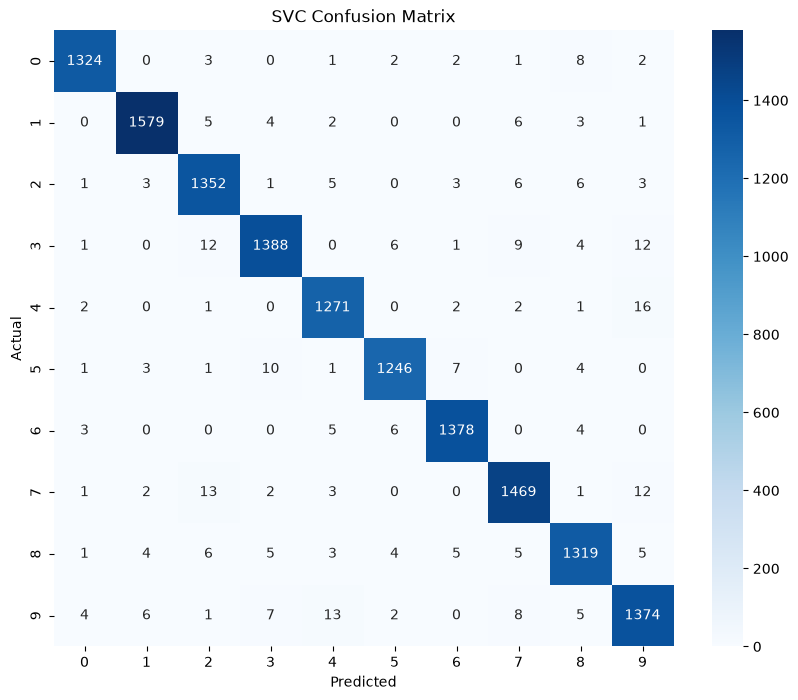

In [29]:
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
plt.title('SVC Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig("svc_confusion_matrix.png")
plt.show()

Training Random Forest Model

In [30]:
rf_model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)


y_pred_rf = rf_model.predict(X_test)


accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"  Random Forest Accuracy : {accuracy_rf * 100:.2f}%")

  Random Forest Accuracy : 96.75%


Training Logistic Regression Model

In [31]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr_model.fit(X_train, y_train)


y_pred_lr = lr_model.predict(X_test)


accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"  Logistic Regression Accuracy : {accuracy_lr * 100:.2f}%")


c:\Users\USER\OneDrive\Desktop\Aya\Machan learning\Aya_Machane_learning\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


  Logistic Regression Accuracy : 92.04%


Training LightGBM Model

In [32]:
lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.08,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)


lgbm_model.fit(X_train, y_train)


y_pred_lgbm = lgbm_model.predict(X_test)


accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)
print(f"  LightGBM Accuracy : {accuracy_lgbm * 100:.2f}%")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.082244 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 108666
[LightGBM] [Info] Number of data points in the train set: 56000, number of used features: 626
[LightGBM] [Info] Start training from score -2.309754
[LightGBM] [Info] Start training from score -2.188460
[LightGBM] [Info] Start training from score -2.300801
[LightGBM] [Info] Start training from score -2.283483
[LightGBM] [Info] Start training from score -2.315345
[LightGBM] [Info] Start training from score -2.407946
[LightGBM] [Info] Start training from score -2.324247
[LightGBM] [Info] Start training from score -2.269219
[LightGBM] [Info] Start training from score -2.326439
[LightGBM] [Info] Start training from score -2.313718
  LightGBM Accuracy : 98.03%


In [ ]:
lgbm_model2 = LGBMClassifier(
    objective='multiclass',
    num_class=10,
    random_state=42,
    n_jobs=-1
)


lgbm_model.fit(X_train, y_train)


y_pred_lgbm = lgbm_model.predict(X_test)


accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)
print(f"  LightGBM Accuracy : {accuracy_lgbm * 100:.2f}%")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.087733 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 108666
[LightGBM] [Info] Number of data points in the train set: 56000, number of used features: 626
[LightGBM] [Info] Start training from score -2.309754
[LightGBM] [Info] Start training from score -2.188460
[LightGBM] [Info] Start training from score -2.300801
[LightGBM] [Info] Start training from score -2.283483
[LightGBM] [Info] Start training from score -2.315345
[LightGBM] [Info] Start training from score -2.407946
[LightGBM] [Info] Start training from score -2.324247
[LightGBM] [Info] Start training from score -2.269219
[LightGBM] [Info] Start training from score -2.326439
[LightGBM] [Info] Start training from score -2.313718
  LightGBM Accuracy : 98.03%


In [36]:

accuracy_results = {
    "XGBoost": accuracy_score(y_test, y_pred),             
    "SVC": accuracy_score(y_test, y_pred_svc),
    "Random Forest": accuracy_score(y_test, y_pred_rf),
    "Logistic Regression": accuracy_score(y_test, y_pred_lr),
    "LightGBM": accuracy_score(y_test, y_pred_lgbm),
    "lgbm_model2": accuracy_score(y_test, y_pred_lgbm)
}

df_results = pd.DataFrame(list(accuracy_results.items()), columns=['Model', 'Accuracy (%)'])
df_results['Accuracy (%)'] = (df_results['Accuracy (%)'] * 100).round(2)
df_results = df_results.sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)

print("=" * 45)
print(" مقارنة دقة الخوارزميات:")
print("=" * 45)
display(df_results)
print("=" * 45)

best_name = df_results.iloc[0]['Model']
best_score = df_results.iloc[0]['Accuracy (%)']
print(f" أفضل خوارزمية هي: {best_name} بنسبة دقة: {best_score}%")

 مقارنة دقة الخوارزميات:


,Model,Accuracy (%)
0,XGBoost,98.18
1,SVC,98.18
2,lgbm_model2,98.03
3,LightGBM,98.03
4,Random Forest,96.75
5,Logistic Regression,92.04


 أفضل خوارزمية هي: XGBoost بنسبة دقة: 98.18%


In [37]:
joblib.dump(xgb_model, "best_model_xgboost_mnist.pkl")

['best_model_xgboost_mnist.pkl']

In [41]:
import os
import numpy as np
from PIL import Image
import joblib
import argparse

# Allowed file extensions
ALLOWED_EXTENSIONS = {'png', 'jpg', 'jpeg', 'gif'}

class_names = {
    0: '0',
    1: '1',
    2: '2',
    3: '3',
    4: '4',
    5: '5',
    6: '6',
    7: '7',
    8: '8',
    9: '9'
}

def allowed_file(filename):
    return '.' in filename and \
           filename.rsplit('.', 1)[1].lower() in ALLOWED_EXTENSIONS

def preprocess_image(image_path):
    img = Image.open(image_path).convert('L')
    
    img = img.resize((28, 28))
    img_array = np.array(img)
    
  
    img_array = img_array / 255.0
    
    
    img_array = img_array.flatten()
    
    return img_array

def predict(image_path, model_path):
    if not os.path.exists(model_path):
        print(f"Error: Model not found at {model_path}")
        return

    if not os.path.exists(image_path):
        print(f"Error: Image not found at {image_path}")
        return

    try:
      
        print(f"Loading model from {model_path}...")
        model = joblib.load(model_path)

     
        print(f"Processing image {image_path}...")
        img_array = preprocess_image(image_path)

       
        prediction = model.predict([img_array])
        class_id = prediction[0]
        class_name = class_names.get(class_id, "Unknown")

        if hasattr(model, "predict_proba"):
            confidence = np.max(model.predict_proba([img_array])) * 100
            print(f"Prediction: {class_name} (Confidence: {confidence:.2f}%)")
        else:
            print(f"Prediction: {class_name}")

    except Exception as e:
        print(f"An error occurred: {e}")

if __name__ == "__main__":
  
    DEFAULT_MODEL_PATH = r'best_model_xgboost_mnist.pkl'
    DEFAULT_IMAGE_PATH = r'C:\Users\USER\OneDrive\Desktop\Aya\Machan learning\Machine_learning_Fils\test_4.png'

    parser = argparse.ArgumentParser(description="Test MNIST Digit Model")
    parser.add_argument("--image", type=str, default=DEFAULT_IMAGE_PATH, help="Path to the image file")
    parser.add_argument("--model", type=str, default=DEFAULT_MODEL_PATH, help="Path to the model pickle file")

    args, unknown = parser.parse_known_args()

    if unknown:
        print(f"Note: Ignoring unknown arguments: {unknown}")

    model_path = args.model
    if not os.path.exists(model_path) and os.path.exists("best_model_xgboost_mnist.pkl"):
        model_path = "best_model_xgboost_mnist.pkl"

    predict(args.image, model_path)

Note: Ignoring unknown arguments: ['--f=c:\\Users\\USER\\AppData\\Roaming\\jupyter\\runtime\\kernel-v3cf1d6067d1a28d49203d90efa1ac6576d187e2f9.json']
Loading model from best_model_xgboost_mnist.pkl...
Processing image C:\Users\USER\OneDrive\Desktop\Aya\Machan learning\Machine_learning_Fils\test_4.png...
Prediction: 3 (Confidence: 99.99%)


طبعاً الاجابه صحيحه  الصوره كانت رقم 3 بخلفيه سودا وكتابه بيضاء 